In [3]:
import pennylane as qp
from pennylane import numpy as np
import matplotlib.pyplot as plt
import jax
from jax import numpy as jnp  # Needed for pulse programming

jax.config.update("jax_platform_name", "cpu")  # Tell jax to use CPU by default
jax.config.update("jax_enable_x64", True)

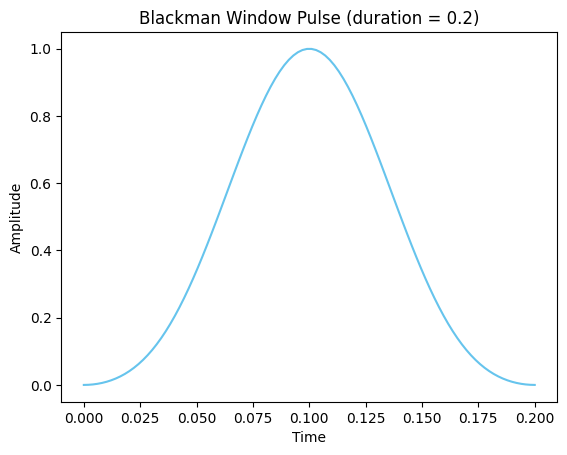

In [5]:
duration = 0.2  # We'll set all of our pulses' duration to 0.2


def blackman_window(peak, time):

    blackman = (
        peak * 0.42
        - 1 / 2 * peak * jnp.cos(2 * jnp.pi * time / duration)
        + peak * 0.08 * jnp.cos(4 * jnp.pi * time / duration)
    )

    return blackman


t_points = np.linspace(0, duration, 100)
y_points = [blackman_window(1, t) for t in t_points]

plt.xlabel("Time", fontsize=10)
plt.ylabel("Amplitude", fontsize=10)

plt.title(f"Blackman Window Pulse (duration = {duration})")
plt.plot(t_points, y_points, c="#66c4ed")
plt.show()

In [6]:
from pennylane.pulse import rydberg_drive as H_d

# Choose some arbitrary parameters
peak = 2
phase = np.pi / 2
detuning = 0

# For now, let's act on only one neutral atom
single_qubit_dev = qp.device("default.qubit", wires=1)


@qp.qnode(single_qubit_dev)
def state_evolution():

    # Use qp.evolve to find the final state of the atom after interacting with the pulse
    qp.evolve(H_d(blackman_window, phase, detuning, wires=[0]))([peak], t=[0, duration])

    return qp.state()


print("The final state is {}".format(state_evolution().round(2)))

ImportError: Module jax is required for the ``ParametrizedEvolution`` class. You can install jax via: pip install jax

In [7]:
def H_i(distance, coupling):

    # Only two atoms, placed in the coordinates (0,0) and (0,r)
    atomic_coordinates = [[0, 0], [0, distance]]

    # Return the interaction term for two atoms in terms of the distance
    return qp.pulse.rydberg_interaction(
        atomic_coordinates, interaction_coeff=coupling, wires=[0, 1]
    )

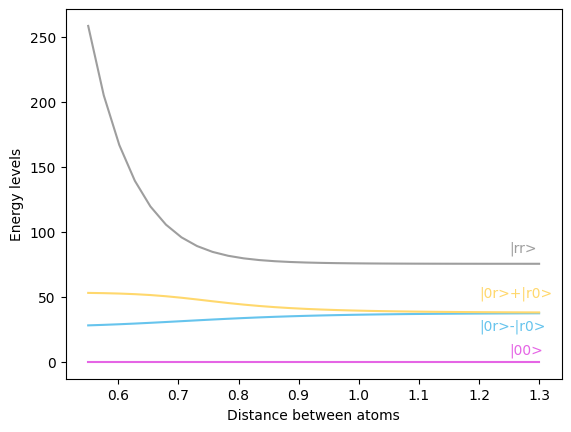

In [8]:
peak = 6
phase = np.pi / 2
detuning = 0
coupling = 1
time = 0.1


def energy_gap(distance):
    """Calculates the energy eigenvalues for the full Hamiltonian, as a function
    of the distance between the atoms."""

    # create the terms
    drive_term = H_d(blackman_window, phase, detuning, wires=[0, 1])
    interaction_term = H_i(distance, coupling)

    # combine and evaluate the Hamiltonian with peak and time parameters
    H = (interaction_term + drive_term)([peak], time)

    # Calculate the eigenvalues for the full Hamiltonian
    eigenvalues = jnp.linalg.eigvals(qp.matrix(H))
    return jnp.sort(eigenvalues - eigenvalues[0])


distances = np.linspace(0.55, 1.3, 30)
energies = [np.real(energy_gap(d)) for d in distances]

plot_colors = ["#e565e5", "#66c4ed", "#ffd86d", "#9e9e9e"]

for i in range(4):
    y = [result[i] for result in energies]
    plt.plot(distances, y, c=plot_colors[i])

plt.xlabel("Distance between atoms")
plt.ylabel("Energy levels")

plt.text(1.25, 85, "|rr>", c="#9e9e9e")
plt.text(1.2, 50, "|0r>+|r0>", c="#ffd86d")
plt.text(1.2, 25, "|0r>-|r0>", c="#66c4ed")
plt.text(1.25, 6, "|00>", c="#e565e5")
plt.show()

In [9]:
def two_pi_pulse(distance, coupling, wires=[0]):

    # Build full Hamiltonian
    full_hamiltonian = H_d(blackman_window, 0, 0, wires) + H_i(distance, coupling)

    # Return the 2 pi pulse
    qp.evolve(full_hamiltonian)([2 * jnp.pi / 0.42 / 0.2 / (2 * jnp.pi)], t=[0, 0.2])


def pi_pulse(distance, coupling, wires=[0]):

    full_hamiltonian = H_d(blackman_window, 0, 0, wires) + H_i(distance, coupling)

    # Return the pi pulse
    qp.evolve(full_hamiltonian)([jnp.pi / 0.42 / 0.2 / (2 * jnp.pi)], t=[0, 0.2])

In [10]:
dev_two_qubits = qp.device("default.qubit", wires=2)


@qp.qnode(dev_two_qubits)
def neutral_atom_CZ(distance, coupling):

    pi_pulse(distance, coupling, wires=[0])

    two_pi_pulse(distance, coupling, wires=[1])

    pi_pulse(distance, coupling, wires=[0])

    return qp.state()


print(
    "The final state after the set of pulses is {} when atoms are close.".format(
        neutral_atom_CZ(0.2, 1).round(2)
    )
)
print(
    "The final state after the set of pulses is {} when atoms are far.".format(
        neutral_atom_CZ(2, 1).round(2)
    )
)

ImportError: Module jax is required for the ``ParametrizedEvolution`` class. You can install jax via: pip install jax